# Interpret the selected genes and XGBoost predictions

Companion to [gene_interactions.ipynb](gene_interactions.ipynb). First inspect
the CV-selected six-gene XGBoost model using SHAP. Then ask whether the
**SPI1–MNDA–LYZ expression signal** tracks estimated myeloid RNA contributions,
and whether its association with TB remains after accounting for study differences
and estimated RNA contributions from different cell groups.

Reuse the main notebook's completed selections, model settings, predictions,
and exact VST input export. This notebook refits only the selected XGBoost model
and verifies its predictions; it does not rerun GFS or change the classifiers.
Run the main notebook first if these exports are missing. Install the shared
`gene_interactions.requirements.txt` in the `cfrna-tb` environment.

These are exploratory analyses of previously inspected data, including genes
selected using training outcomes. Estimated RNA contributions are not measured
cell counts, and adjusted associations do not establish cellular mechanisms.

**Patient-level evaluation panels.** The cell after each model comparison shows score distributions and patient predictions. `Train (apparent)` means predictions on the people used to fit the model. HIV-positive IDs carry `[HIV+]`; unrecorded status carries `[HIV?]`. The threshold line uses the recorded paper GLM threshold or the classifier's stated default boundary; no test-based threshold selection is performed. Decision scores are not probabilities. With one stored fit per model, ranked scores and errors are shown, not a fraction across repeated random splits. PDF detail pages and TSV tables in `Figure_Output/Model_Evaluation/` preserve every sample ID. HIV subgroup differences are descriptive and do not establish their cause.

Plot design reference: [Gardella et al., PNAS 2025, Fig. 3](https://pmc.ncbi.nlm.nih.gov/articles/PMC12377778/). The original R `Figure_1.ipynb` and hash-frozen `Figure_2.ipynb` remain unchanged; the paper GLM's available individual predictions are included here. Aggregate AUCs without stored individual predictions cannot support a patient-level panel.

## 1. Load the completed model analysis

Match all exported inputs and predictions by sample ID and keep the original
feature order. Figures and tables retain the shared output folder.

In [1]:
import hashlib
import json
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy.special import expit
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier

SEED = 87
current = Path.cwd().resolve()
REPOSITORY = next(p for p in [current, *current.parents]
                  if (p / "Files_For_Manuscript/counts.train.tsv").is_file())
DATA = REPOSITORY / "Files_For_Manuscript"
OUTPUT = REPOSITORY / "Figure_Output/Gene_Interactions/focused"
GFS_OUTPUT = OUTPUT / "gfs"
SPLIT_NAMES = {"train": "Training", "test": "Test", "val": "Validation"}
# Keep analytical keys stable; use explicit labels in figures and displayed tables.
ADJUSTMENT_LABELS = {
    "Unadjusted": "Unadjusted",
    "Cohort": "Study",
    "Cohort + composition": "Study + RNA mix (4 groups)",
    "Finer composition": "Study + RNA mix (6 groups)",
}
sns.set_theme(style="ticks", context="paper")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                    "axes.labelsize": 10, "axes.titlesize": 11,
                    "axes.spines.top": False, "axes.spines.right": False,
                    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42})

def save_figure(figure, name):
    for suffix in ["png", "pdf"]:
        figure.savefig(OUTPUT / f"{name}.{suffix}", bbox_inches="tight")

def positive_scores(model, features):
    assert np.array_equal(model.classes_, [0, 1])
    return model.predict_proba(features)[:, 1]

split_metadata = {s: pd.read_csv(DATA / f"metadata.{s}.tsv", sep="\t", index_col="sample_id")
                  for s in SPLIT_NAMES}
split_labels = {s: m.tb.eq("positive").astype(int).to_numpy() for s, m in split_metadata.items()}
y_train = split_labels["train"]
vst_path = GFS_OUTPUT / "expression_vst.csv"
assert vst_path.exists(), "Run the main notebook's GFS setup cell to export expression_vst.csv."
vst = pd.read_csv(vst_path, index_col=["split", "sample_id"])
assert vst.index.is_unique
gfs_inputs = {s: vst.xs(s).loc[m.index] for s, m in split_metadata.items()}
candidate_table = pd.read_csv(DATA / "gene_interactions_reference/paper_input_audit/training_candidates.tsv",
                              sep="\t", index_col="gene_id")
gene_names_by_id = candidate_table.gene_name.to_dict()
gfs_gene_sets = {}
for variant in ["cv", "cv_refined"]:
    selected = pd.read_csv(GFS_OUTPUT / f"{variant}_selected_genes.csv")
    gfs_gene_sets[(variant, "XGBClassifier")] = selected.loc[
        selected.model.eq("XGBClassifier")].sort_values("order").gene_id.tolist()
model_settings = json.loads((GFS_OUTPUT / "settings.json").read_text())
gfs_templates = {"XGBClassifier": make_pipeline(
    SimpleImputer(strategy="mean"), StandardScaler(),
    XGBClassifier(**model_settings["models"]["XGBClassifier"]))}
saved_scores = pd.read_csv(OUTPUT / "gfs_prediction_scores.csv")
def load_predictions(feature_set):
    scores = saved_scores.loc[saved_scores.model.eq("XGBClassifier") & saved_scores.feature_set.eq(feature_set)]
    assert not scores.duplicated(["split", "sample_id"]).any()
    return {"XGBClassifier": {
        s: scores.loc[scores.split.eq(s)].set_index("sample_id").loc[m.index, "score"].to_numpy()
        for s, m in split_metadata.items()}}
cv_gfs_predictions = load_predictions("GFS: CV AUC")
cv_refined_predictions = load_predictions("GFS: CV AUC + revisions")

## 2. Inspect SHAP patterns in the CV-selected XGBoost model

Explain the six-gene panel **GBP5, AHNAK, JMJD1C, MNDA, LYZ, SPI1** selected
by fivefold-CV AUC. The forward and revised searches gave the same panel.
Refit its existing pipeline once on training, keeping the selected gene order,
settings, and split-specific VST inputs. Check every prediction against the
existing CV results; do not rerun feature selection or tune on the holdouts.

Use XGBoost's native, exact TreeSHAP (tree-path-dependent) implementation;
no additional package is needed. Contributions plus the model baseline sum to
the **TB-positive log odds**. Positive SHAP pushes the prediction toward TB;
negative SHAP pushes it away. These are not probability changes. Training
explanations describe the final fitted model, not out-of-fold predictions.
The same model and baseline explain all three splits.

References: [XGBoost prediction API](https://xgboost.readthedocs.io/en/release_3.0.0/python/python_api.html#xgboost.Booster.predict)
and [TreeSHAP interpretation](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).

In [2]:
from xgboost import DMatrix

shap_genes = gfs_gene_sets[("cv", "XGBClassifier")]
shap_names = [gene_names_by_id[gene] for gene in shap_genes]
assert shap_genes == gfs_gene_sets[("cv_refined", "XGBClassifier")]
shap_inputs = {split: features[shap_genes] for split, features in gfs_inputs.items()}
with threadpool_limits(limits=1):
    shap_model = clone(gfs_templates["XGBClassifier"]).fit(shap_inputs["train"], y_train)
shap_booster = shap_model.steps[-1][1].get_booster()
shap_values, shap_interactions, shap_scaled = {}, {}, {}
shap_rows, shap_checks = [], []
for split, features in shap_inputs.items():
    shap_scaled[split] = shap_model[:-1].transform(features)
    matrix = DMatrix(shap_scaled[split])
    contributions = shap_booster.predict(matrix, pred_contribs=True, approx_contribs=False)
    interactions = shap_booster.predict(matrix, pred_interactions=True, approx_contribs=False)
    margin = shap_booster.predict(matrix, output_margin=True)
    probabilities = positive_scores(shap_model, features)
    np.testing.assert_allclose(probabilities, cv_gfs_predictions["XGBClassifier"][split], rtol=0, atol=1e-7)
    np.testing.assert_allclose(probabilities, cv_refined_predictions["XGBClassifier"][split], rtol=0, atol=1e-7)
    np.testing.assert_allclose(contributions.sum(axis=1), margin, rtol=0, atol=1e-5)
    np.testing.assert_allclose(expit(contributions.sum(axis=1)), probabilities, rtol=0, atol=1e-6)
    np.testing.assert_allclose(interactions.sum(axis=2), contributions, rtol=0, atol=1e-5)
    shap_values[split] = contributions[:, :-1]
    shap_interactions[split] = interactions[:, :-1, :-1]
    shap_checks.append({"split": split, "n": len(features),
                        "auc": roc_auc_score(split_labels[split], probabilities),
                        "max_margin_error": float(abs(contributions.sum(axis=1) - margin).max())})
    for j, gene in enumerate(shap_names):
        shap_rows.append(pd.DataFrame({
            "split": split, "sample_id": features.index, "tb_positive": split_labels[split],
            "gene_id": shap_genes[j], "gene": gene, "expression_vst": features.iloc[:, j].to_numpy(),
            "expression_training_z": shap_scaled[split][:, j], "shap_log_odds": contributions[:, j],
            "baseline_log_odds": contributions[:, -1], "predicted_probability": probabilities,
        }))
shap_data = pd.concat(shap_rows, ignore_index=True)
shap_data.to_csv(OUTPUT / "xgboost_cv_shap_values.csv", index=False)
pd.DataFrame(shap_checks).to_csv(OUTPUT / "xgboost_cv_shap_checks.csv", index=False)
print(f"Verified SHAP additivity and existing predictions for {sum(row['n'] for row in shap_checks)} samples.")

Verified SHAP additivity and existing predictions for 251 samples.


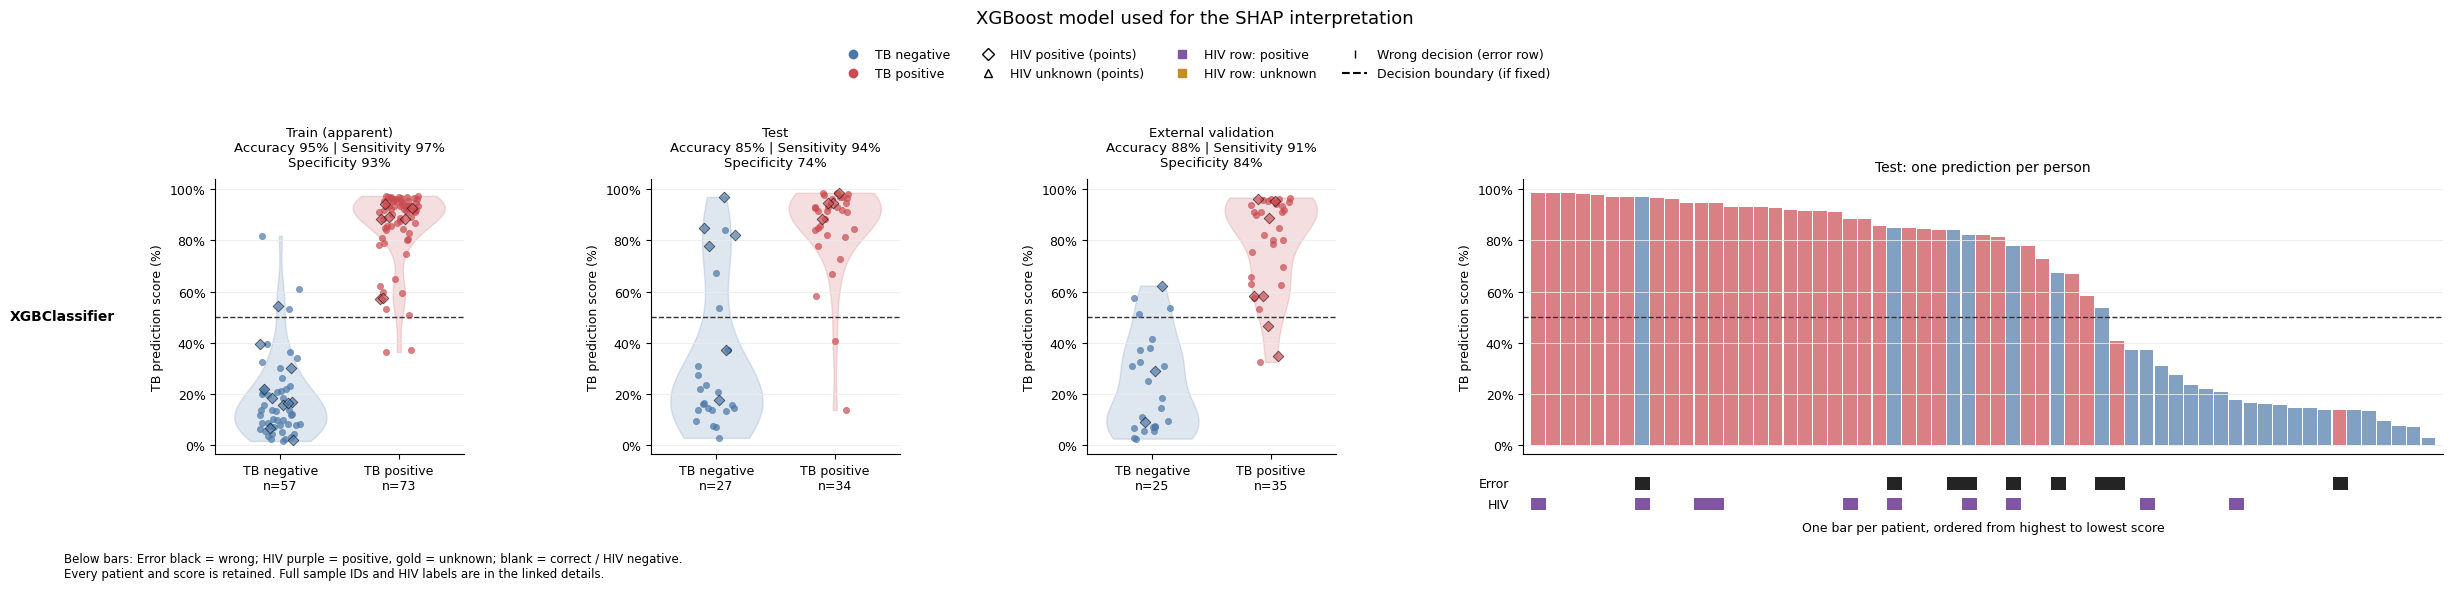

[All sample IDs with HIV markers (PDF)](../Figure_Output/Model_Evaluation/xgb_selected_samples.pdf) · [Searchable patient table](../Figure_Output/Model_Evaluation/xgb_selected_samples.html)

In [1]:
# Patient-level evaluation of the models in the preceding cell.
# Keep every patient bar; align Error/HIV rows below the bars for legibility.
import sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plot_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                 if (p / "Files_For_Manuscript/metadata.train.tsv").is_file())
helper_path = str(plot_root / "Scripts_For_Manuscript")
if helper_path not in sys.path:
    sys.path.insert(0, helper_path)
from evaluation_panels import plot_comparison
panel_predictions_to_plot = {"GFS: CV AUC": cv_gfs_predictions} if "cv_gfs_predictions" in globals() else None
evaluation_figure = plot_comparison(plot_root, "xgb_selected", predictions=panel_predictions_to_plot)
plt.show()
display(Markdown("[All sample IDs with HIV markers (PDF)](../Figure_Output/Model_Evaluation/xgb_selected_samples.pdf) · [Searchable patient table](../Figure_Output/Model_Evaluation/xgb_selected_samples.html)"))

### Which genes influence predictions, and in which direction?

Each dot is one sample. Color shows expression standardized using **training**
means and standard deviations, with the same color limits across splits.
All panels use one SHAP axis and one gene order, ranked by training mean absolute
SHAP. The table gives average contribution magnitude in log-odds units;
it measures influence on predictions, not accuracy or biological importance.

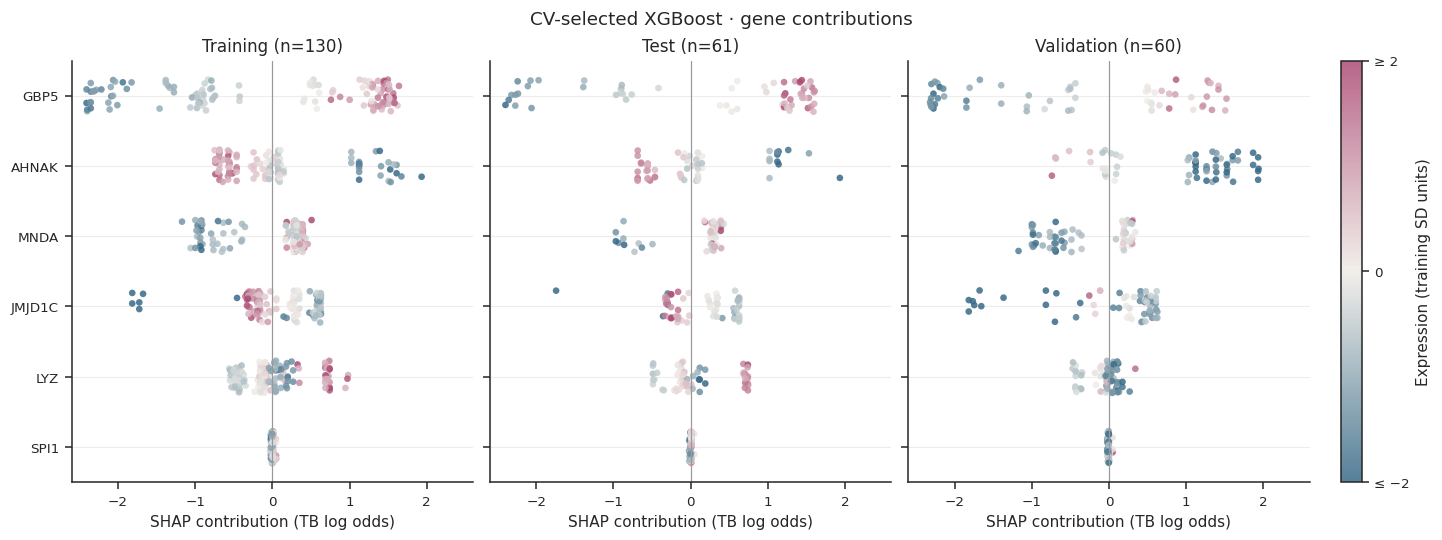

,Training,Test,Validation
Gene,,,
GBP5,1.325,1.359,1.296
AHNAK,0.488,0.499,1.027
MNDA,0.441,0.390,0.523
JMJD1C,0.397,0.388,0.586
LYZ,0.312,0.311,0.157
SPI1,0.009,0.009,0.010


In [3]:
shap_importance = pd.DataFrame({
    SPLIT_NAMES[split]: np.abs(values).mean(axis=0) for split, values in shap_values.items()
}, index=pd.Index(shap_names, name="Gene")).sort_values("Training", ascending=False)
shap_importance.to_csv(OUTPUT / "xgboost_cv_shap_importance.csv")
shap_order = [shap_names.index(gene) for gene in shap_importance.index]
shap_color_map = LinearSegmentedColormap.from_list("expression", ["#386A87", "#F0EDE7", "#AC4B75"])
shap_limit = 1.08 * max(np.abs(values).max() for values in shap_values.values())
random = np.random.default_rng(SEED)
figure, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharex=True, sharey=True, layout="constrained")
for axis, (split, values) in zip(axes, shap_values.items()):
    for position, j in enumerate(shap_order):
        points = axis.scatter(values[:, j], position + random.uniform(-0.23, 0.23, len(values)),
                              c=shap_scaled[split][:, j], cmap=shap_color_map, vmin=-2, vmax=2,
                              s=19, alpha=0.85, linewidths=0)
    axis.axvline(0, color="0.6", linewidth=0.8)
    axis.set(yticks=range(len(shap_names)), yticklabels=shap_importance.index,
             ylim=(len(shap_names) - 0.5, -0.5), xlim=(-shap_limit, shap_limit),
             title=f"{SPLIT_NAMES[split]} (n={len(values)})", xlabel="SHAP contribution (TB log odds)")
    axis.grid(axis="y", color="0.93")
colorbar = figure.colorbar(points, ax=axes, fraction=0.025, pad=0.025, ticks=[-2, 0, 2])
colorbar.ax.set_yticklabels(["≤ −2", "0", "≥ 2"])
colorbar.set_label("Expression (training SD units)")
figure.suptitle("CV-selected XGBoost · gene contributions")
save_figure(figure, "xgboost_cv_shap_summary")
plt.show()
display(shap_importance.style.format("{:.3f}").set_caption("Mean absolute SHAP (log odds)"))

### How does each gene's expression relate to its contribution?

Plot the original VST expression against its SHAP contribution. Steps and
plateaus reflect the fitted trees. Vertical spread at similar expression can
reflect other genes' contributions to the attribution. Each gene has its own
axis limits so smaller effects remain visible; split colors and markers are
consistent. These are observed sample explanations, not intervention curves.

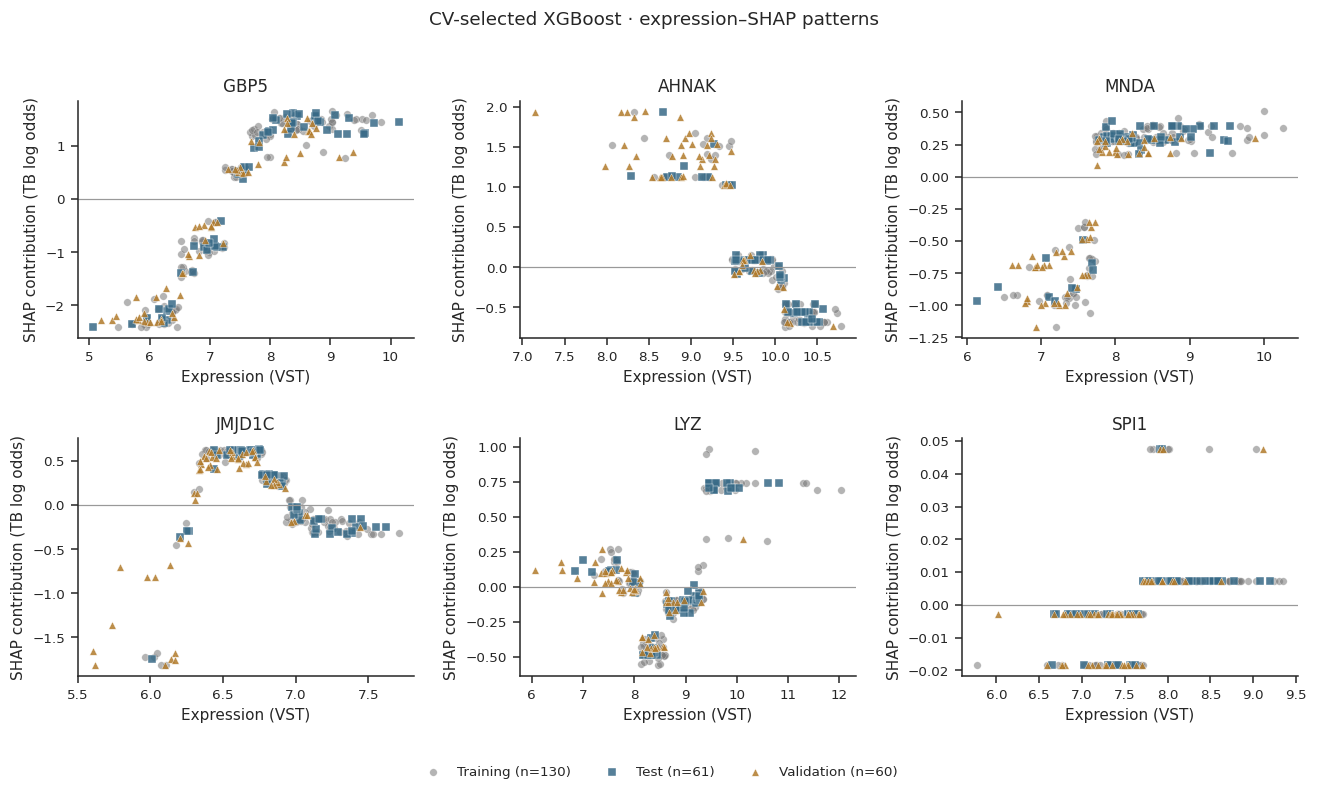

In [4]:
shap_split_colors = {"train": "#777777", "test": "#386A87", "val": "#B17A2A"}
shap_split_markers = {"train": "o", "test": "s", "val": "^"}
figure, axes = plt.subplots(2, 3, figsize=(12, 7.2))
for axis, j in zip(axes.flat, shap_order):
    for split, features in shap_inputs.items():
        axis.scatter(features.iloc[:, j], shap_values[split][:, j],
                     color=shap_split_colors[split], marker=shap_split_markers[split],
                     s=24, alpha=0.55 if split == "train" else 0.85, linewidths=0.3,
                     edgecolors="white", label=f"{SPLIT_NAMES[split]} (n={len(features)})")
    axis.axhline(0, color="0.6", linewidth=0.8)
    axis.set(title=shap_names[j], xlabel="Expression (VST)", ylabel="SHAP contribution (TB log odds)")
handles, labels = axes.flat[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
figure.suptitle("CV-selected XGBoost · expression–SHAP patterns")
figure.tight_layout(rect=(0, 0.06, 1, 0.96), h_pad=2, w_pad=2)
save_figure(figure, "xgboost_cv_shap_dependence")
plt.show()

### Which gene pairs have interaction contributions in this model?

The diagonal of the TreeSHAP interaction matrix contains main effects; exclude
it here. Each off-diagonal entry contains half a pair's contribution, so report
**mean absolute `2 × interaction[i, j]`** for each unordered pair. Use the same
gene order and color scale for all splits. Values describe model nonadditivity,
not physical interactions, biological epistasis, or statistical significance.

These tree-path-dependent explanations use the fitted tree structure and
training node cover as the reference. Correlated genes can share attribution;
rankings depend on that reference, the fitted model, and the samples explained.
SHAP does not remove the existing feature-selection or normalization limitations.

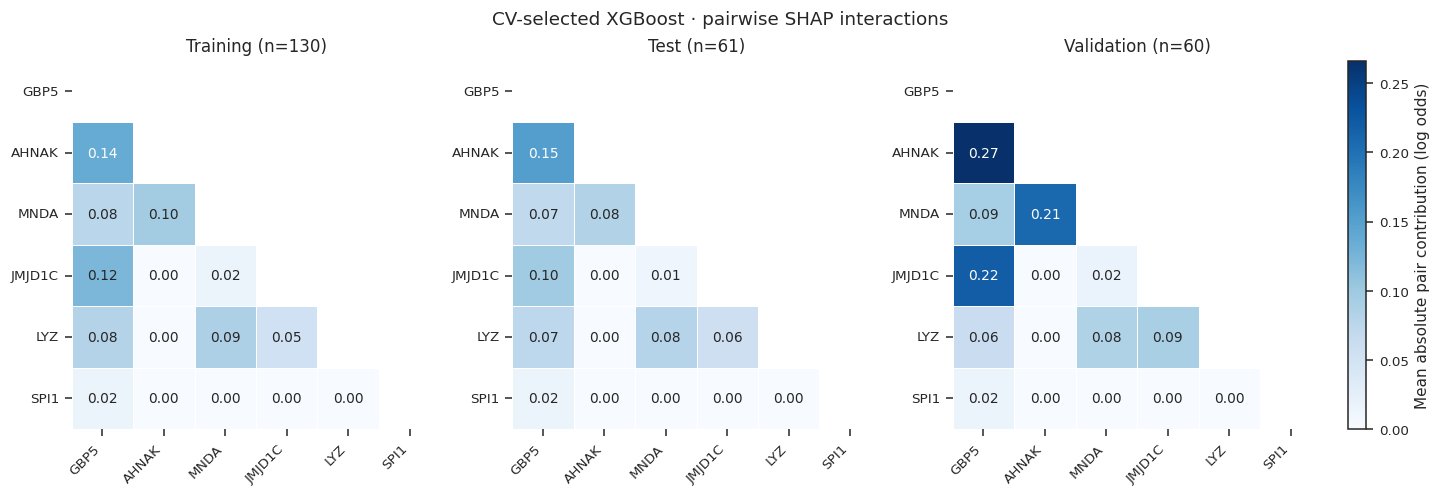

In [5]:
shap_pair_rows = []
shap_pair_matrices = {}
for split, values in shap_interactions.items():
    pair_strength = np.abs(2 * values).mean(axis=0)
    shap_pair_matrices[split] = pair_strength[np.ix_(shap_order, shap_order)]
    for i in range(len(shap_names)):
        for j in range(i + 1, len(shap_names)):
            shap_pair_rows.append({"split": split, "gene_1": shap_names[i], "gene_2": shap_names[j],
                                   "mean_abs_pair_log_odds": pair_strength[i, j]})
shap_pairs = pd.DataFrame(shap_pair_rows)
shap_pairs.to_csv(OUTPUT / "xgboost_cv_shap_interactions.csv", index=False)
# Retain signed sample-level matrices for inspecting individual pairs later.
np.savez_compressed(OUTPUT / "xgboost_cv_shap_interaction_values.npz",
                    genes=np.array(shap_names), **shap_interactions,
                    **{f"{split}_sample_ids": features.index.to_numpy(dtype=str)
                       for split, features in shap_inputs.items()})
pair_limit = shap_pairs.mean_abs_pair_log_odds.max()
figure, axes = plt.subplots(1, 3, figsize=(13, 4.4), layout="constrained")
for axis, (split, values) in zip(axes, shap_pair_matrices.items()):
    sns.heatmap(values, mask=np.triu(np.ones_like(values, dtype=bool)), ax=axis,
                cmap="Blues", vmin=0, vmax=pair_limit, annot=True, fmt=".2f", cbar=False,
                xticklabels=shap_importance.index, yticklabels=shap_importance.index,
                square=True, linewidths=0.5, annot_kws={"fontsize": 9})
    axis.set_title(f"{SPLIT_NAMES[split]} (n={len(shap_inputs[split])})")
    axis.set_xticklabels(axis.get_xticklabels(), rotation=45, ha="right")
    axis.set_yticklabels(axis.get_yticklabels(), rotation=0)
colorbar = figure.colorbar(axes[0].collections[0], ax=axes, fraction=0.025, pad=0.02)
colorbar.set_label("Mean absolute pair contribution (log odds)")
figure.suptitle("CV-selected XGBoost · pairwise SHAP interactions")
save_figure(figure, "xgboost_cv_shap_interactions")
plt.show()

### What the current SHAP patterns show

- **GBP5 is the main contributor in every split.** Higher expression generally pushes predictions toward TB; low expression pushes them away. MNDA has a similar threshold-like direction but a smaller contribution.
- **AHNAK has an inverse pattern:** lower expression pushes toward TB. Its mean absolute contribution is substantially larger in validation than in training or test, indicating a different distribution of explanations under the same model.
- **JMJD1C and LYZ are non-monotonic.** JMJD1C contributes positively over an intermediate expression range; both very low and high values can contribute negatively. LYZ has several steps, including a negative region at intermediate expression. Their direction cannot be summarized reliably by one coefficient or correlation.
- **SPI1 has very little influence in the final fitted model.** Selection optimized the mean AUC of five separately fitted fold models; being accepted during selection does not guarantee a large SHAP contribution after refitting on all training samples. Its biological plausibility should not be confused with predictive importance here.
- **GBP5–AHNAK is the strongest average pair contribution in all three splits.** GBP5–JMJD1C and AHNAK–MNDA also stand out. These are hypotheses about the fitted prediction rule, not evidence that the proteins interact or that changing either gene would alter TB risk.

Differences between splits reflect the samples and their preprocessing under one
fixed model. They are descriptive, without uncertainty intervals or a test of
biological mechanism. The existing test and validation AUCs measure ranking
performance; SHAP provides a separate explanation of those predictions.

## 3. A separate check: three genes and the cells contributing plasma RNA

This check asks whether **SPI1, MNDA and LYZ** track the estimated share of plasma
RNA from myeloid cells, such as monocytes and neutrophils. It is a separate
question from explaining the six-gene XGBoost classifier above.

**Average of SPI1, MNDA and LYZ** means one number per participant: put each
gene's expression on a comparable scale using its training mean and standard
deviation, then average the three values with equal weights. For example, scaled
values of 1, 2 and 3 give an average of 2. This is not the XGBoost prediction.
Its unit is the average of the gene-level standardized values; the average itself
is not rescaled to have a standard deviation of one.

**RNA mix** means the estimated
share of plasma RNA originating from each group. For example, a sample with more
RNA from neutrophils can have higher expression of neutrophil-related genes even
without higher expression within each neutrophil. Accounting for these estimates
checks whether a TB difference remains after allowing for different RNA mixtures;
it cannot establish what happens inside individual cells.

The figures compare these factors:

| Figure label | What the statistical model accounts for |
|---|---|
| Unadjusted | TB-positive versus TB-negative expression only |
| Study | Which study recruited the participant |
| Study + RNA mix (4 groups) | Study plus RNA shares from myeloid cells, lymphoid cells, erythroid/platelet sources, and all other sources |
| Study + RNA mix (6 groups) | Study plus a more detailed grouping that separates erythroid, platelet and endothelial sources |

Validation contains one study, so its models have no between-study term.

The existing plasma estimates in `Files_For_Manuscript/discovery_cell_types.tsv`
cover all 251 modeled participants. The [study's methods](https://pmc.ncbi.nlm.nih.gov/articles/PMC11164910/)
describe BayesPrism with a Tabula Sapiens reference; [BayesPrism](https://pmc.ncbi.nlm.nih.gov/articles/PMC9046084/)
estimates RNA-read contributions, **not cell counts**. All participants must have
complete, unique matches.

Myeloid sources here are monocytes, macrophages, neutrophils, conventional dendritic
cells, myeloid progenitors, basophils and mast cells. Platelet/erythroid sources are
kept separate. The model uses `log(group / other)` for each non-reference group
because all shares sum to one. All groups are positive, so no pseudocount is
needed. Exact group membership is exported alongside the results.


In [6]:
signal_genes = ["SPI1", "MNDA", "LYZ"]
metadata = pd.concat([m.assign(split=s) for s, m in split_metadata.items()])
assert metadata.index.is_unique
fractions_all = pd.read_csv(DATA / "discovery_cell_types.tsv", sep="\t", index_col="sample_id")
assert fractions_all.index.is_unique and metadata.index.isin(fractions_all.index).all()
fractions = fractions_all.loc[metadata.index]
assert np.isfinite(fractions.to_numpy()).all() and (fractions >= 0).all().all()
np.testing.assert_allclose(fractions.sum(axis=1), 1, rtol=0, atol=1e-8)
signal_expression = pd.concat([
    pd.DataFrame(shap_scaled[s], index=features.index, columns=shap_names)[signal_genes]
    for s, features in shap_inputs.items()
]).loc[metadata.index]
analysis = metadata[["split", "cohort", "tb"]].join(signal_expression)
analysis["tb_positive"] = analysis.tb.eq("positive").astype(int)
analysis["three_gene_signal"] = signal_expression.mean(axis=1)
assert not analysis.isna().any().any()

myeloid_types = ["Monocyte", "Macrophage", "neutrophil", "Mature.conventional.dendritic.cell",
                 "Myeloid.progenitor", "Basophil", "Mast.cell"]
rna_groups = {
    "myeloid": myeloid_types,
    "lymphoid": ["NK.Cell", "B.cell", "T.Cell", "Plasmablast", "Thymocyte"],
    "erythroid_platelet": ["Erythrocyte.erythroid.progenitor", "Platelet"],
}
assigned = [cell for members in rna_groups.values() for cell in members]
assert len(assigned) == len(set(assigned))
rna_groups["other"] = [cell for cell in fractions if cell not in assigned]
grouped = pd.DataFrame({group: fractions[members].sum(axis=1) for group, members in rna_groups.items()})
fine_groups = {"myeloid": myeloid_types, "lymphoid": rna_groups["lymphoid"],
               "erythroid": ["Erythrocyte.erythroid.progenitor"], "platelet": ["Platelet"],
               "endothelial": ["Endothelial.cell"]}
fine_assigned = [cell for members in fine_groups.values() for cell in members]
fine_groups["other"] = [cell for cell in fractions if cell not in fine_assigned]
fine_grouped = pd.DataFrame({g: fractions[m].sum(axis=1) for g, m in fine_groups.items()})
composition_columns, fine_columns = [], []
for prefix, values, columns in [("rna", grouped, composition_columns), ("fine", fine_grouped, fine_columns)]:
    assert (values > 0).all().all()
    np.testing.assert_allclose(values.sum(axis=1), 1, rtol=0, atol=1e-8)
    for group in values.columns.drop("other"):
        column = f"{prefix}_{group}_vs_other"
        analysis[column] = np.log(values[group] / values["other"])
        columns.append(column)
analysis["myeloid_fraction"] = grouped.myeloid
analysis.to_csv(OUTPUT / "myeloid_analysis_inputs.csv")
grouped.to_csv(OUTPUT / "myeloid_rna_groups.csv")
(OUTPUT / "myeloid_group_definitions.json").write_text(json.dumps(
    {"primary": rna_groups, "sensitivity": fine_groups}, indent=2))
display(pd.crosstab([analysis.split, analysis.cohort], analysis.tb).reindex(SPLIT_NAMES, level=0))

tb              negative  positive
split cohort                      
train GHL             24        39
      R2D2            33        34
test  GHL             12        18
      R2D2            15        16
val   TBSQUARE        25        35

## 4. Three-gene expression and myeloid RNA

**Figure legend.** Each dot is a participant; color shows TB status and shape shows
study. The three-gene mean averages SPI1, MNDA and LYZ after each gene is scaled
using its training mean and standard deviation (z scores). Myeloid RNA is the
estimated percentage of plasma RNA from the myeloid groups defined above, not
a cell count. **r** is the Spearman correlation; **adjusted r** is the correlation
of ranked values after removing study and TB-status terms. These are descriptive
associations, without significance tests. Within-study and individual-gene results
are also saved.


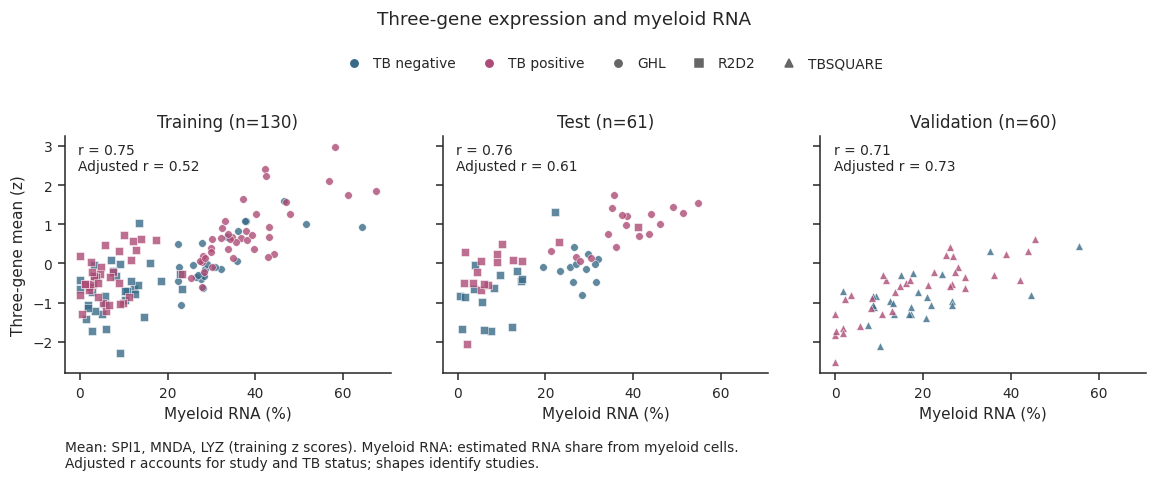

In [7]:
def make_design(frame, covariates):
    numeric = [name for name in covariates if name != "cohort"]
    design = frame[numeric].astype(float).copy()
    if "cohort" in covariates:
        design = design.join(pd.get_dummies(frame.cohort, prefix="cohort", drop_first=True, dtype=float))
    design = sm.add_constant(design, has_constant="add")
    assert np.linalg.matrix_rank(design) == design.shape[1]
    return design

correlation_rows = []
for split, frame in analysis.groupby("split", sort=False):
    for signal in ["three_gene_signal", *signal_genes]:
        ranked = frame[[signal, "myeloid_fraction"]].rank()
        nuisance = make_design(frame, ["cohort", "tb_positive"])
        residuals = ranked.to_numpy() - nuisance @ np.linalg.lstsq(nuisance, ranked, rcond=None)[0]
        correlation_rows.append({"split": split, "cohort": "All", "signal": signal, "n": len(frame),
            "spearman_rho": spearmanr(frame[signal], frame.myeloid_fraction).statistic,
            "partial_rank_r": np.corrcoef(np.asarray(residuals).T)[0, 1]})
        for cohort, subset in frame.groupby("cohort"):
            correlation_rows.append({"split": split, "cohort": cohort, "signal": signal, "n": len(subset),
                "spearman_rho": spearmanr(subset[signal], subset.myeloid_fraction).statistic})
myeloid_correlations = pd.DataFrame(correlation_rows)
myeloid_correlations.to_csv(OUTPUT / "myeloid_signal_correlations.csv", index=False)
primary_correlations = myeloid_correlations.query("signal == 'three_gene_signal' and cohort == 'All'").set_index("split")

tb_colors = {"negative": "#386A87", "positive": "#AC4B75"}
cohort_markers = {"GHL": "o", "R2D2": "s", "TBSQUARE": "^"}
figure, axes = plt.subplots(1, 3, figsize=(10.8, 4.4), sharex=True, sharey=True)
for axis, split in zip(axes, SPLIT_NAMES):
    frame = analysis.loc[analysis.split.eq(split)]
    for (cohort, tb), subset in frame.groupby(["cohort", "tb"]):
        axis.scatter(100 * subset.myeloid_fraction, subset.three_gene_signal,
                     c=tb_colors[tb], marker=cohort_markers[cohort], s=25, alpha=0.8,
                     edgecolors="white", linewidths=0.4)
    row = primary_correlations.loc[split]
    axis.set(title=f"{SPLIT_NAMES[split]} (n={len(frame)})", xlabel="Myeloid RNA (%)")
    axis.text(0.04, 0.97, f"r = {row.spearman_rho:.2f}\nAdjusted r = {row.partial_rank_r:.2f}",
              transform=axis.transAxes, ha="left", va="top", fontsize=9)
    axis.tick_params(labelsize=9)
axes[0].set_ylabel("Three-gene mean (z)")
handles = [Line2D([], [], color=color, marker="o", linestyle="", label=f"TB {tb}") for tb, color in tb_colors.items()]
handles += [Line2D([], [], color="0.4", marker=marker, linestyle="", label=cohort) for cohort, marker in cohort_markers.items()]
figure.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.54, 0.92),
              ncol=5, frameon=False, fontsize=9, handletextpad=0.4, columnspacing=1.4)
figure.suptitle("Three-gene expression and myeloid RNA", fontsize=12, y=0.99)
figure.subplots_adjust(left=0.08, right=0.99, bottom=0.24, top=0.73, wspace=0.16)
figure.text(0.08, 0.04,
            "Mean: SPI1, MNDA, LYZ (training z scores). Myeloid RNA: estimated RNA share from myeloid cells.\n"
            "Adjusted r accounts for study and TB status; shapes identify studies.",
            ha="left", va="bottom", fontsize=9)
save_figure(figure, "myeloid_signal_scatter")
plt.show()


**Figure legend — gene expression and myeloid RNA sources.** Columns show the
three-gene mean and each gene separately; rows show myeloid RNA sources. Colors
and numbers give Spearman correlations with estimated RNA shares. Positive values
indicate that expression and RNA share tend to rise together. Myeloid total sums
the listed cell types. These are descriptive associations, not cell counts or
causal effects.

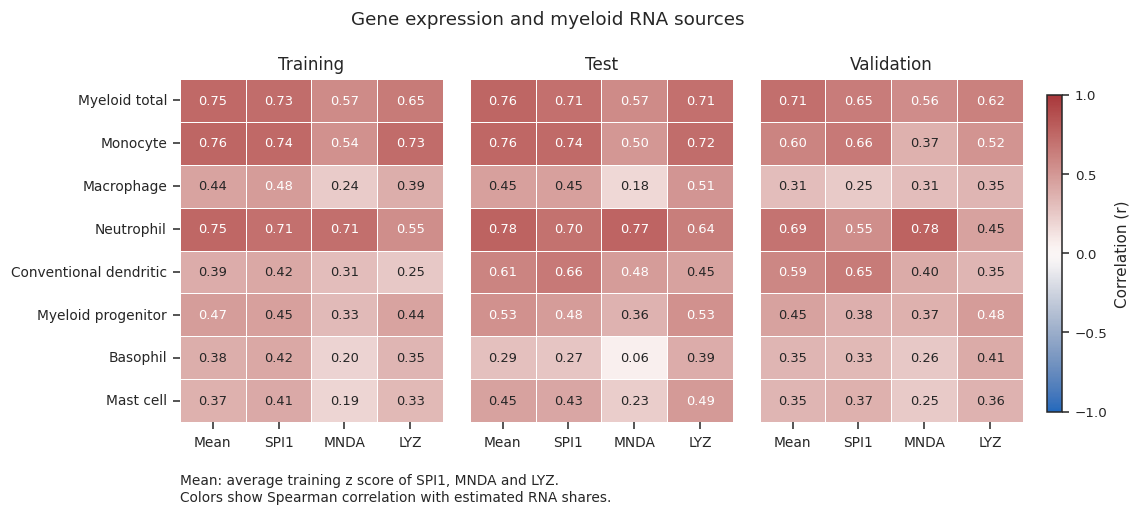

In [8]:
cell_labels = {"Myeloid total": "Myeloid total", "Monocyte": "Monocyte", "Macrophage": "Macrophage",
               "neutrophil": "Neutrophil", "Mature.conventional.dendritic.cell": "Conventional dendritic",
               "Myeloid.progenitor": "Myeloid progenitor", "Basophil": "Basophil", "Mast.cell": "Mast cell"}
source_fractions = fractions[myeloid_types].copy()
source_fractions.insert(0, "Myeloid total", grouped.myeloid)
cell_correlation_rows = []
figure, axes = plt.subplots(1, 3, figsize=(10.8, 4.8))
for axis, split in zip(axes, SPLIT_NAMES):
    frame = analysis.loc[analysis.split.eq(split)]
    matrix = pd.DataFrame({signal: [spearmanr(frame[signal], source_fractions.loc[frame.index, cell]).statistic
                                   for cell in source_fractions]
                           for signal in ["three_gene_signal", *signal_genes]}, index=source_fractions.columns)
    cell_correlation_rows.append(matrix.rename_axis("cell_type").reset_index().assign(split=split))
    sns.heatmap(matrix, ax=axis, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", cbar=False,
                yticklabels=[cell_labels[c] for c in matrix.index] if axis is axes[0] else False,
                xticklabels=["Mean", *signal_genes],
                linewidths=0.5, annot_kws={"fontsize": 8.5})
    axis.set(title=SPLIT_NAMES[split], xlabel="", ylabel="")
    axis.set_yticklabels(axis.get_yticklabels(), rotation=0)
    axis.set_xticklabels(axis.get_xticklabels(), rotation=0, ha="center")
    axis.tick_params(labelsize=9)
figure.subplots_adjust(left=0.19, right=0.90, bottom=0.20, top=0.85, wspace=0.10)
color_axis = figure.add_axes([0.92, 0.22, 0.013, 0.60])
figure.colorbar(axes[0].collections[0], cax=color_axis,
               label="Correlation (r)", ticks=[-1, -0.5, 0, 0.5, 1])
figure.suptitle("Gene expression and myeloid RNA sources", fontsize=12, y=0.98)
figure.text(0.19, 0.045,
            "Mean: average training z score of SPI1, MNDA and LYZ.\n"
            "Colors show Spearman correlation with estimated RNA shares.",
            ha="left", va="bottom", fontsize=9)
save_figure(figure, "myeloid_source_correlations")
plt.show()
pd.concat(cell_correlation_rows, ignore_index=True).to_csv(OUTPUT / "myeloid_source_correlations.csv", index=False)

## 5. TB-associated expression

**Figure legend.** **a**, Mean expression of SPI1, MNDA and LYZ, compared across
four adjustment models. **b**, Each gene separately, adjusted for study and the
four-group RNA mix. Points are TB-positive minus TB-negative differences; bars
are 95% confidence intervals. Zero means no difference. Expression is scaled
using each gene's training mean and standard deviation (z units); the three-gene
mean is not rescaled to its own standard deviation.

**Study** accounts for the recruiting study. **RNA mix** means estimated RNA shares
from different cell groups, not cell counts. The four-group model uses myeloid,
lymphoid, erythroid/platelet and other sources. The six-group model separates
erythroid, platelet and endothelial sources. Validation includes one study,
so its models have no between-study term.

**Statistical details.** Fit expression as the response and TB status as the exposure:

`expression = intercept + TB difference × TB-positive + study terms + RNA-share terms`

Use OLS with [HC3 heteroskedasticity-robust standard errors](https://www.statsmodels.org/v0.14.6/generated/statsmodels.regression.linear_model.OLSResults.get_robustcov_results.html)
and residual-df t-based 95% confidence intervals. The intervals are exploratory,
not corrected for gene selection or multiple comparisons. Uncertainty in the
estimated RNA shares is not propagated into the intervals.


Dataset,Adjustment,n,TB difference,95% CI lower,95% CI upper
Training,Unadjusted,130,0.606,0.314,0.898
Training,Study,130,0.492,0.257,0.727
Training,Study + RNA mix (4 groups),130,0.366,0.082,0.650
Training,Study + RNA mix (6 groups),130,0.346,0.071,0.622
Test,Unadjusted,61,0.870,0.479,1.260
Test,Study,61,0.798,0.468,1.127
Test,Study + RNA mix (4 groups),61,0.642,0.248,1.036
Test,Study + RNA mix (6 groups),61,0.739,0.348,1.131
Validation,Unadjusted,60,0.212,-0.125,0.549
Validation,Study,60,0.212,-0.125,0.549


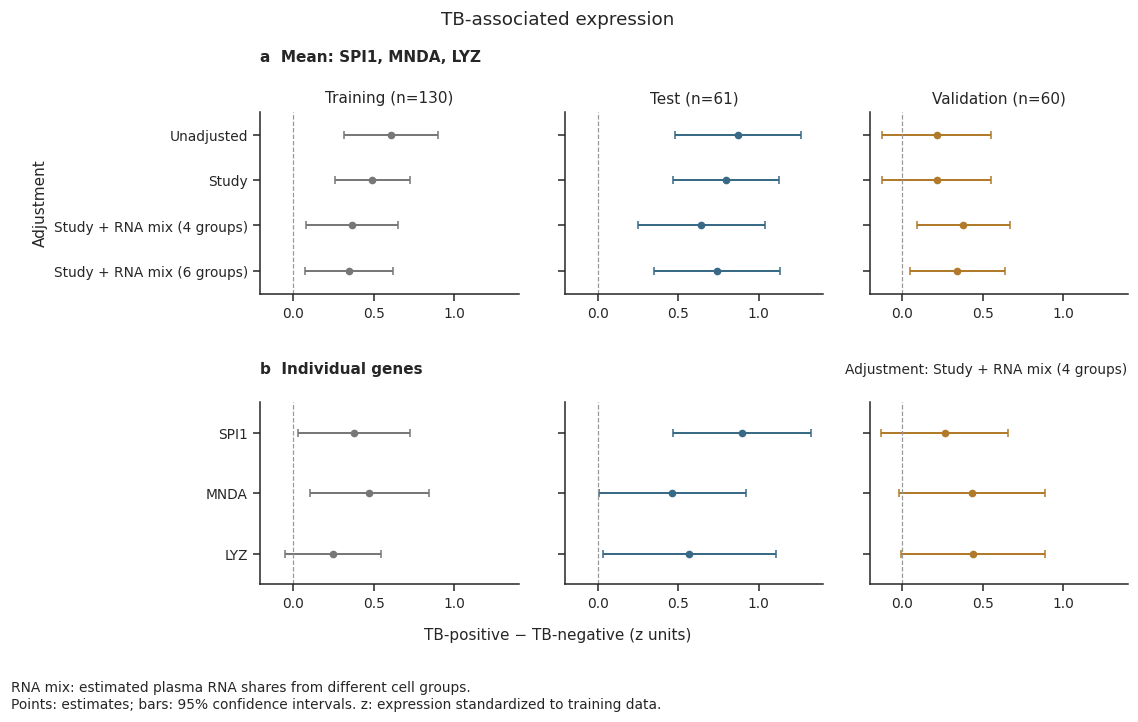

In [9]:
association_specs = {
    "Unadjusted": [],
    "Cohort": ["cohort"],
    "Cohort + composition": ["cohort", *composition_columns],
    "Finer composition": ["cohort", *fine_columns],
}
association_rows = []
for split, frame in analysis.groupby("split", sort=False):
    for label, controls in association_specs.items():
        design = make_design(frame, ["tb_positive", *controls])
        for signal in ["three_gene_signal", *signal_genes]:
            fit = sm.OLS(frame[signal], design, missing="raise").fit(cov_type="HC3", use_t=True)
            lower, upper = fit.conf_int().loc["tb_positive"]
            association_rows.append({"split": split, "signal": signal, "adjustment": label,
                "n": len(frame), "parameters": design.shape[1], "tb_difference": fit.params.tb_positive,
                "ci_lower": lower, "ci_upper": upper, "nominal_p": fit.pvalues.tb_positive,
                "design_condition_number": np.linalg.cond(design)})
myeloid_associations = pd.DataFrame(association_rows)
assert np.isfinite(myeloid_associations.select_dtypes("number")).all().all()
myeloid_associations.to_csv(OUTPUT / "myeloid_tb_associations.csv", index=False)
primary_associations = myeloid_associations.query("signal == 'three_gene_signal'")
display(primary_associations[["split", "adjustment", "n", "tb_difference", "ci_lower", "ci_upper"]]
        .replace({"split": SPLIT_NAMES,
                  "adjustment": {key: value.replace("\n", " ") for key, value in ADJUSTMENT_LABELS.items()}})
        .rename(columns={"split": "Dataset", "adjustment": "Adjustment", "tb_difference": "TB difference",
                         "ci_lower": "95% CI lower", "ci_upper": "95% CI upper"})
        .style.format(precision=3).hide(axis="index"))

figure, axes = plt.subplots(2, 3, figsize=(10.8, 6.6), sharex=True)
split_colors = {"train": "#777777", "test": "#386A87", "val": "#B17A2A"}
for column, split in enumerate(SPLIT_NAMES):
    top = primary_associations.loc[primary_associations.split.eq(split)].set_index("adjustment").loc[list(association_specs)]
    bottom = myeloid_associations.loc[myeloid_associations.split.eq(split) &
        myeloid_associations.adjustment.eq("Cohort + composition") &
        myeloid_associations.signal.isin(signal_genes)].set_index("signal").loc[signal_genes]
    for axis, table, labels in [(axes[0, column], top, [ADJUSTMENT_LABELS[key] for key in association_specs]),
                                 (axes[1, column], bottom, signal_genes)]:
        axis.errorbar(table.tb_difference, np.arange(len(table)),
                       xerr=[table.tb_difference-table.ci_lower, table.ci_upper-table.tb_difference],
                       fmt="o", color=split_colors[split], capsize=2.5, linewidth=1.3, markersize=4)
        axis.axvline(0, color="0.6", linestyle="--", linewidth=0.8)
        axis.set(yticks=range(len(table)), yticklabels=labels, ylim=(len(table)-0.5, -0.5))
        axis.tick_params(axis="y", labelleft=column == 0, labelsize=9)
        axis.tick_params(axis="x", labelbottom=True, labelsize=9)
        axis.locator_params(axis="x", nbins=4)
    axes[0, column].set_title(f"{SPLIT_NAMES[split]} (n={len(analysis.loc[analysis.split.eq(split)])})", fontsize=10)
axes[0, 0].set_ylabel("Adjustment", fontsize=10)
figure.suptitle("TB-associated expression", fontsize=12, y=0.99)
figure.text(0.25, 0.92, "a  Mean: SPI1, MNDA, LYZ", fontsize=10, weight="bold")
figure.text(0.25, 0.49, "b  Individual genes", fontsize=10, weight="bold")
figure.text(0.98, 0.49, "Adjustment: Study + RNA mix (4 groups)", ha="right", fontsize=9)
figure.subplots_adjust(left=0.25, right=0.98, bottom=0.20, top=0.85, hspace=0.60, wspace=0.18)
figure.supxlabel("TB-positive − TB-negative (z units)", y=0.12, fontsize=10)
figure.text(0.04, 0.025,
            "RNA mix: estimated plasma RNA shares from different cell groups.\n"
            "Points: estimates; bars: 95% confidence intervals. z: expression standardized to training data.",
            ha="left", va="bottom", fontsize=9)
save_figure(figure, "myeloid_tb_adjusted_associations")
plt.show()


## 6. Read the results and their limits

Correlations and adjusted TB differences answer complementary questions. An
expression signal can track relative myeloid RNA contributions and still have
a residual TB association. Adjustment can also increase an association; it need
not remove it. Compare the finer-group sensitivity before treating a residual
association as robust to the chosen grouping.

Fractions and gene expression derive from the same cfRNA measurements. The
local deconvolution pipeline contains several reference/gene-filter variants,
and the exact variant producing the manuscript table is not documented locally.
We cannot exclude contribution of SPI1, MNDA or LYZ to those estimates.
The RNA shares can themselves change with disease, so adjustment is not a causal
decomposition into mixture versus cellular activation. Coarse cell groups,
measurement error and remaining study/site or clinical differences can also
leave residual association. An independent cell measure would help test the RNA-source explanation.
The [optional gene-excluded deconvolution check](gene_interactions_deconvolution.ipynb)
tests direct reliance on those genes. It is not required for these completed
analyses and does not by itself establish a cell-intrinsic response.

In the current results, the three-gene average has a positive adjusted association in all
three datasets under both group definitions. Validation's unadjusted interval
crosses zero, whereas the adjusted association is larger; adjustment does not
simply attenuate the signal. In validation, each individual gene's primary-adjusted
interval still includes zero. Interpret the three-gene average as an aggregate signal,
not three independently established gene effects.

The [cohort and clinical follow-up](gene_interactions_cohort_clinical.ipynb)
also separates monocyte and neutrophil contributions. Under that finer myeloid
adjustment, the training and validation intervals include zero. The broad-group
results here therefore do not establish a TB response independent of the estimated RNA sources.

In [10]:
takeaways = []
for split in SPLIT_NAMES:
    row = primary_associations.loc[primary_associations.split.eq(split) &
                                   primary_associations.adjustment.eq("Cohort + composition")].iloc[0]
    fine = primary_associations.loc[primary_associations.split.eq(split) &
                                    primary_associations.adjustment.eq("Finer composition")].iloc[0]
    rho = primary_correlations.loc[split, "spearman_rho"]
    takeaways.append(f"- **{SPLIT_NAMES[split]}:** myeloid correlation **ρ={rho:.3f}**; "
                    f"TB difference accounting for study and RNA shares from four cell groups **{row.tb_difference:.3f}** "
                    f"(95% CI {row.ci_lower:.3f} to {row.ci_upper:.3f}); "
                    f"using six cell groups **{fine.tb_difference:.3f}** "
                    f"({fine.ci_lower:.3f} to {fine.ci_upper:.3f}).")
display(Markdown("**Observed results from this run:**\n\n" + "\n".join(takeaways)))
input_paths = [vst_path, GFS_OUTPUT / "settings.json", GFS_OUTPUT / "cv_selected_genes.csv",
               GFS_OUTPUT / "cv_refined_selected_genes.csv", OUTPUT / "gfs_prediction_scores.csv",
               DATA / "discovery_cell_types.tsv", *[DATA / f"metadata.{s}.tsv" for s in SPLIT_NAMES]]
(OUTPUT / "interpretation_provenance.json").write_text(json.dumps({
    "input_sha256": {str(p.relative_to(REPOSITORY)): hashlib.sha256(p.read_bytes()).hexdigest() for p in input_paths},
    "packages": {p: version(p) for p in ["numpy", "pandas", "scipy", "statsmodels", "xgboost-cpu"]},
    "signal": "Mean training z score of SPI1, MNDA, LYZ; fixed positive equal weights",
    "primary_adjustment": "cohort + log(myeloid/other) + log(lymphoid/other) + log(erythroid_platelet/other)",
    "intervals": "HC3 robust covariance, residual-df t, 95%, exploratory",
}, indent=2))
print(f"Saved interpretation figures and tables: {OUTPUT}")

**Observed results from this run:**

- **Training:** myeloid correlation **ρ=0.749**; TB difference accounting for study and RNA shares from four cell groups **0.366** (95% CI 0.082 to 0.650); using six cell groups **0.346** (0.071 to 0.622).
- **Test:** myeloid correlation **ρ=0.759**; TB difference accounting for study and RNA shares from four cell groups **0.642** (95% CI 0.248 to 1.036); using six cell groups **0.739** (0.348 to 1.131).
- **Validation:** myeloid correlation **ρ=0.714**; TB difference accounting for study and RNA shares from four cell groups **0.378** (95% CI 0.089 to 0.666); using six cell groups **0.340** (0.045 to 0.635).

Saved interpretation figures and tables: /local/workdir/amz63/cfRNA_TB/Figure_Output/Gene_Interactions/focused


## 7. Continue with the biological follow-ups

- [Expression patterns and patient groups](gene_interactions_patterns.ipynb): six-gene heatmap, broader PCA, training-fitted UMAP, and bootstrap clustering stability. The stable training groups largely reproduce study membership and estimated RNA shares; they are not established TB subtypes.
- [Cohort and clinical checks](gene_interactions_cohort_clinical.ipynb): age, sex, HIV, cohort-specific effects, read-depth sensitivity, accounting for more detailed myeloid RNA sources, and Xpert Ultra burden. Separating monocyte and neutrophil contributions weakens the training and validation TB associations; the broad-group result above is sensitive to how finely the RNA sources are grouped. The burden association does not replicate across splits.
- [Pathway analysis](gene_interactions_pathways.ipynb): full-expression enrichment and participant-level scores that exclude the six selected genes and account for estimated RNA contributions from different cell groups. The interferon-gamma score is associated with TB across all three splits; this pathway score uses genes beyond the six selected by XGBoost.
- [Optional deconvolution robustness check](gene_interactions_deconvolution.ipynb): compare matched estimates with and without the six XGBoost genes. The completed analyses above use the existing plasma fractions and do not depend on this rerun.

`Files_For_Manuscript/cto_wb.txt` contains distinct whole-blood RNA estimates for 60 matched validation participants. A paired plasma/whole-blood comparison is an optional extension; this notebook uses the plasma estimates.

Together, these analyses distinguish predictive contributions, broader disease-associated expression, study differences, and estimated RNA-source differences. They do not establish a physical gene interaction or a cell-intrinsic mechanism.

Figure presentation follows the compact labels and separate legends in
[Nature Medicine, Fig. 2 (Tessier et al.)](https://www.nature.com/articles/s41591-025-03570-5/figures/2)
and [Nature Medicine, Extended Data Fig. 2 (Barnett et al.)](https://pmc.ncbi.nlm.nih.gov/articles/PMC11645277/#Fig7),
with units and editable text retained according to the
[Nature figure guide](https://research-figure-guide.nature.com/figures/preparing-figures-our-specifications/).
These are presentation references; the analytical methods and results are unchanged.
